# 09 · Error analysis of the final model

Where does the final LightGBM (4 groups, `lgbm_4groups`) go wrong? Everything comes from its saved out-of-fold
predictions, compared with the best baseline (last-3 table). Nothing is trained here. If a model of Duong's
turns out best in `08_model_comparison`, change the file name in Cell 1 and run this again.

1. Which events are hardest to predict
2. Does more history help
3. Are the chances honest (calibration)
4. The most common mistakes

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from eventflow.config import EVENT_CLASSES, FIGURES_DIR, N_CLASSES
from eventflow.data import load_train, make_train_examples
from eventflow.metrics import clip_and_normalize
from eventflow.validation import PROBA_COLS, add_folds, load_oof

# The saved out-of-fold predictions: one row per practice question, from the model that did NOT see
# its machine. Prefix length and the test-like flag come from the questions themselves.
examples = add_folds(make_train_examples(load_train()))
final = load_oof("lgbm_4groups").merge(examples[["sequence_id", "last_row", "prefix_len", "is_mimic"]],
                                       on=["sequence_id", "last_row"], validate="one_to_one")
base = load_oof("last3_table")                                   # best baseline, for comparison
assert (final[["sequence_id", "last_row"]].to_numpy() == base[["sequence_id", "last_row"]].to_numpy()).all()

y = final["target"].to_numpy()                                   # the real next event of each question
rows = np.arange(len(y))
P = clip_and_normalize(final[PROBA_COLS].to_numpy())             # same clipping as the official score so no log(0) instead log(0.000000001) for eg
P_base = clip_and_normalize(base[PROBA_COLS].to_numpy())
final["chance"] = P[rows, y]                                     # chance given to the real next event
final["loss"] = -np.log(final["chance"])                         # penalty of each question
final["loss_base"] = -np.log(P_base[rows, y])
final["top_guess"] = P.argmax(axis=1)                            # the model's most likely event
final["right"] = final["top_guess"] == final["target"]           # was the top guess the real event?
print(f"{len(final):,} questions | LightGBM {final['loss'].mean():.4f} | last-3 table {final['loss_base'].mean():.4f}") # cal the loss of the final and base model for every questions

596,953 questions | LightGBM 1.4801 | last-3 table 1.6441


When the real next event is X, how well did the model do?

In [ ]:
# 1. Which events are hardest? For each REAL next event: how common it is, the average penalty,
# its share of all the loss, the average chance the model gave it, and how often it was the top guess.
g = final.groupby("target") #Group the questions by their real next event: all questions where RECOVERY came next in one group, all where COOLING_FAULT came next in another, and so on. That's 14 groups.
by_event = pd.DataFrame({
    "share of questions": g.size() / len(final), #how common this event is as the answer
    "loss": g["loss"].mean(), #LightGBM's average penalty on these questions
    "loss (last-3 table)": g["loss_base"].mean(),#the baseline's average penalty
    "chance given": g["chance"].mean(),#the average chance LightGBM gave the real event
    "top guess right": g["right"].mean(), #how often the top guess was this event
})
by_event["share of total loss"] = by_event["share of questions"] * by_event["loss"] / final["loss"].mean()  #What fraction of all the penalty points come from this event. It combines how common with how hard
by_event["gain vs table"] = by_event["loss (last-3 table)"] - by_event["loss"] #How much better LightGBM is than the baseline for this event
by_event.index = [EVENT_CLASSES[i] for i in by_event.index]
by_event.sort_values("share of total loss", ascending=False).round(3)

,share of questions,loss,loss (last-3 table),chance given,top guess right,share of total loss,gain vs table
MAINTENANCE_CHECK,0.139,1.612,1.732,0.245,0.287,0.151,0.121
TEMP_WARNING,0.116,1.511,1.630,0.295,0.487,0.118,0.119
VIBRATION_WARNING,0.110,1.563,1.735,0.275,0.483,0.116,0.172
RECOVERY,0.307,0.462,0.536,0.700,0.939,0.096,0.075
COMPONENT_REPLACED,0.046,2.638,2.851,0.103,0.062,0.081,0.213
EMERGENCY_STOP,0.043,2.544,2.876,0.125,0.090,0.073,0.332
COOLING_ACTIVATED,0.046,2.229,2.647,0.164,0.156,0.069,0.418
COOLING_FAULT,0.095,1.053,1.280,0.480,0.731,0.068,0.227
LOAD_INCREASE,0.034,2.835,3.113,0.083,0.068,0.064,0.279
LOAD_DECREASE,0.020,3.379,3.649,0.052,0.023,0.046,0.270


In [ ]:
# 2. Does more history help? Average penalty by how many events the question shows.
# (Checked because long histories are rarer in our questions than in the test set; see 02_validation.)
#checks whether the model does better when the question shows more history.
#which range has the highest average penalty
length_bin = pd.cut(final["prefix_len"], [89, 120, 150, 180, 220])
by_length = final.groupby(length_bin, observed=True).agg(
    questions=("loss", "size"), loss=("loss", "mean"), loss_base=("loss_base", "mean"))
by_length["gain vs table"] = by_length["loss_base"] - by_length["loss"]
by_length.round(4)

,questions,loss,loss_base,gain vs table
prefix_len,,,,
"(89, 120]",201441,1.4761,1.6389,0.1628
"(120, 150]",170071,1.4824,1.6445,0.1622
"(150, 180]",125745,1.4899,1.6581,0.1682
"(180, 220]",99696,1.4718,1.6359,0.1640


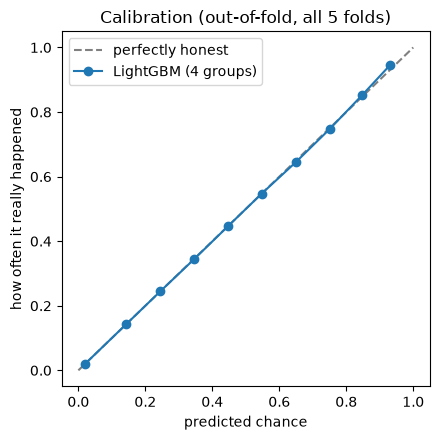

,predicted,happened,count
bin,,,
0,0.020,0.020,6940981
1,0.142,0.142,588491
2,0.245,0.245,279559
3,0.346,0.345,159656
4,0.447,0.446,100830
5,0.548,0.548,72079
6,0.649,0.645,59798
7,0.751,0.748,63491
8,0.848,0.853,64936


In [ ]:
# 3. Are the chances honest (calibration)? Put every predicted chance (14 per question) into 10 bins
# and compare the average predicted chance with how often that event really came next.
# for all quesiton we get the precitons form all the cal the bin for each chances, then we cal the perecnt that event happen in all of the target to compare
p = P.ravel()
happened = (np.arange(N_CLASSES)[None, :] == y[:, None]).ravel()
bin_of = np.minimum((p * 10).astype(int), 9)                     # 0-10%, 10-20%, ..., 90-100%
calib = pd.DataFrame({"predicted": p, "happened": happened, "bin": bin_of}).groupby("bin").agg(
    predicted=("predicted", "mean"), happened=("happened", "mean"), count=("predicted", "size"))

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfectly honest")
ax.plot(calib["predicted"], calib["happened"], "o-", label="LightGBM (4 groups)")
ax.set_xlabel("predicted chance"); ax.set_ylabel("how often it really happened"); ax.legend()
ax.set_title("Calibration (out-of-fold, all 5 folds)")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "err_calibration.png", dpi=150); plt.show()
calib.round(3)

model is not under or overestimating the actuall chances of the event that will happen

When the top guess was wrong, what did it guess instead?

In [ ]:
# 4. The most common mistakes of the top guess: (real event, top guess) pairs when they differ.
wrong = final[~final["right"]] # keep where the top guess is wrong
mistakes = pd.DataFrame({"real": np.array(EVENT_CLASSES)[wrong["target"]],
                         "top guess": np.array(EVENT_CLASSES)[wrong["top_guess"]]})
mistakes = mistakes.value_counts().head(10).rename("questions").reset_index()
mistakes["share of all questions"] = mistakes["questions"] / len(final)
print(f"top guess right on {final['right'].mean():.1%} of questions")
mistakes.round(4)

top guess right on 52.8% of questions


,real,top guess,questions,share of all questions
0,MAINTENANCE_CHECK,VIBRATION_WARNING,15004,0.0251
1,MAINTENANCE_CHECK,COOLING_FAULT,14061,0.0236
2,MAINTENANCE_CHECK,RECOVERY,12454,0.0209
3,MAINTENANCE_CHECK,TEMP_WARNING,12347,0.0207
4,COMPONENT_REPLACED,RECOVERY,12203,0.0204
5,LOAD_INCREASE,RECOVERY,10791,0.0181
6,VIBRATION_WARNING,MAINTENANCE_CHECK,10067,0.0169
7,TEMP_WARNING,VIBRATION_WARNING,9611,0.0161
8,COOLING_ACTIVATED,TEMP_WARNING,9105,0.0153
9,VIBRATION_WARNING,RECOVERY,8614,0.0144


## Notes

**Which events are hardest.** MAINTENANCE_CHECK causes the most loss (15% of the total): it is common (14% of questions), but the top guess is right only 29% of the time, and it is the real event in 4 of the 5 most common mistakes (confused with VIBRATION_WARNING, COOLING_FAULT, RECOVERY and TEMP_WARNING). It still gets 25% on average, so these are close calls rather than surprises. RECOVERY is the easiest (top guess right 94%, loss 0.46); being the most common event (31%), it is also the most common wrong guess. The rarest events (CONTROL_ALERT, ROUTINE_CHECK, PRESSURE_WARNING) are the hardest (loss ~4) and never the top guess, but each is only ~3% of the total loss. LightGBM gains most over the last-3 table on SENSOR_RESET, COOLING_ACTIVATED and EMERGENCY_STOP (+0.33 to +0.42), events that depend on sensors, timing and recency that the last 3 events alone cannot show.

**History length.** Loss does not fall steadily with longer history (1.476, 1.482, 1.490, 1.472); the last-3 baseline shows the same up-and-down pattern, so it comes from the questions, not the model. LightGBM's gain over the baseline is about the same at every length (0.162–0.168). Weighting the ranges like the test set (even over 90–220) gives 1.479, practically the same as 1.480, so having more short histories in our questions does not bias the score.

**Calibration.** Almost perfect: in every 10% bin the predicted chance and the observed frequency differ by at most 0.005, except the top bin (predicted 0.93, observed 0.95; slightly under-confident, 0.3% of all chances). The probabilities are honest, so no extra calibration is needed (figure: `reports/figures/err_calibration.png`).

**Top guess.** Right on 52.8% of questions, against 7% for a random guess and 31% for always guessing RECOVERY. Accuracy is not our score, though: log loss only looks at the chance given to the real event, and when the top guess is wrong the real event usually still gets a fair chance.